# 🖥️ Cloud Infrastructure Telemetry: AWS CloudWatch Traffic Blasts (NAB Benchmark)
## Distributed Server Shocks, Volumetric Traffic Surges & Service Outages

### 1. Incident Background & Multi-Spike Structure
In cloud computing and site reliability engineering (SRE), production infrastructure operates within bounded capacity envelopes. When anomalous events occur—such as **distributed denial-of-service (DDoS) attacks, microservice cascading retry storms, or runaway batch data pipelines**—server metrics experience extreme vertical impulses.

This notebook analyzes high-frequency production telemetry from the **Numenta Anomaly Benchmark (NAB)**, captured from production Amazon Web Services (AWS) EC2 instances at 5-minute sampling intervals.

Key telemetry dynamics:
* **Baseline Operating Regime:** Normal network ingress rate hovers quietly between **50 and 5,000 bytes / 5-min**.
* **Volumetric Surge Shocks:** The instance experiences sudden, vertical packet bursts where incoming traffic explodes to **8,285,420 bytes / 5-min**—a **+16,000,000% vertical surge** that overwhelms ingress network queues and triggers CPU saturation.
* **Cascading Failures:** Multiple recurring surges occur across days, followed by cliff drops as load-balancers drop unresponsive nodes.

### 2. Target Variables ($y$)
* **`network_in_bytes`**: Bytes received per 5-minute window on the network interface.
* **`traffic_velocity`**: First difference rate of change ($\Delta y = y_t - y_{t-1}$).
* **`surge_ratio`**: Current network ingress relative to the 24-hour rolling median.

### 3. Data Source
* **Numenta Anomaly Benchmark (NAB)** open GitHub repository (`realAWSCloudwatch/ec2_network_in_5abac7.csv`).
* Real anonymized AWS production telemetry.


### 📚 Academic Citations & Benchmark Lineage
* **Numenta Anomaly Benchmark:** Ahmad, S., Lavin, A., Purdy, S., & Agha, Z. (2017). *"Evaluating Real-time Anomaly Detection Algorithms – The Numenta Anomaly Benchmark."* *Journal of Machine Learning Research (JMLR)*, 18(1), 1–46.
* **BibTeX Citation:**
```bibtex
@article{ahmad2017evaluating,
  title={Evaluating Real-time Anomaly Detection Algorithms -- The Numenta Anomaly Benchmark},
  author={Ahmad, Subutai and Lavin, Alexander and Purdy, Scott and Agha, Zohair},
  journal={Journal of Machine Learning Research},
  volume={18},
  number={1},
  pages={1--46},
  year={2017}
}
```

In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized successfully!")

Environment initialized successfully!


### 4. Data Ingestion & Local Caching

In [2]:
def fetch_aws_network_telemetry(cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'aws_network_traffic_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading cached AWS CloudWatch telemetry from: {cache_path}")
        df = pd.read_csv(cache_path)
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        return df
    
    print("Downloading raw AWS CloudWatch production metrics from NAB repository...")
    url = 'https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/ec2_network_in_5abac7.csv'
    df = pd.read_csv(url)
    df = df.rename(columns={'value': 'network_in_bytes'})
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df = df.sort_values('timestamp').reset_index(drop=True)
    
    df.to_csv(cache_path, index=False)
    print(f"Downloaded and cached {len(df):,} 5-minute telemetry intervals.")
    return df

df_aws = fetch_aws_network_telemetry()
df_aws.head()

Downloaded and cached 4,730 5-minute telemetry intervals.


,timestamp,network_in_bytes
0,2014-03-01 17:36:00,42.0
1,2014-03-01 17:41:00,94.8
2,2014-03-01 17:46:00,42.0
3,2014-03-01 17:51:00,68.4
4,2014-03-01 17:56:00,68.4


### 5. Server Stress Feature Engineering & Spike Identification

In [3]:
df_aws_proc = df_aws.copy().sort_values('timestamp').reset_index(drop=True)

# Convert to Kilobytes (KB) and Megabytes (MB)
df_aws_proc['network_in_kb'] = df_aws_proc['network_in_bytes'] / 1024.0
df_aws_proc['network_in_mb'] = df_aws_proc['network_in_bytes'] / (1024.0 * 1024.0)

# 1. Traffic velocity (Rate of change in KB per 5-min step)
df_aws_proc['velocity_kb_step'] = df_aws_proc['network_in_kb'].diff()

# 2. 24-hour trailing median baseline (288 steps of 5-min)
df_aws_proc['baseline_24h_median_kb'] = df_aws_proc['network_in_kb'].rolling(288, min_periods=36).median()

# 3. Ingress Surge Ratio
df_aws_proc['surge_ratio'] = df_aws_proc['network_in_kb'] / df_aws_proc['baseline_24h_median_kb'].replace(0, np.nan)

# 4. Rolling 12-hour Z-Score
roll_mean_12h = df_aws_proc['network_in_kb'].rolling(144, min_periods=24).mean()
roll_std_12h = df_aws_proc['network_in_kb'].rolling(144, min_periods=24).std()
df_aws_proc['traffic_zscore_12h'] = (df_aws_proc['network_in_kb'] - roll_mean_12h) / roll_std_12h

# 5. Automated Peak Detection of Volumetric Network Blasts
peaks, _ = find_peaks(df_aws_proc['network_in_mb'].values, height=2.0, distance=36, prominence=1.5)
df_aws_proc['is_traffic_blast'] = 0
df_aws_proc.loc[peaks, 'is_traffic_blast'] = 1

print(f"Total 5-Minute Telemetry Windows:        {len(df_aws_proc):,}")
print(f"Baseline Median Network Ingress:          {df_aws_proc['network_in_kb'].median():.2f} KB / 5-min")
print(f"Peak Network Ingress Reached:             {df_aws_proc['network_in_mb'].max():.2f} MB / 5-min ({df_aws_proc['network_in_bytes'].max():,} bytes)")
print(f"Peak Blast Surge vs Median:               +{df_aws_proc['network_in_bytes'].max() / df_aws_proc['network_in_bytes'].median():,.0f}x baseline")
print(f"Detected Severe Volumetric Blasts (>=2MB): {len(peaks)}")
df_aws_proc.head()

Total 5-Minute Telemetry Windows:        4,730
Baseline Median Network Ingress:          0.07 KB / 5-min
Peak Network Ingress Reached:             7.90 MB / 5-min (8,285,420.0 bytes)
Peak Blast Surge vs Median:               +121,132x baseline
Detected Severe Volumetric Blasts (>=2MB): 32


,timestamp,network_in_bytes,network_in_kb,network_in_mb,velocity_kb_step,baseline_24h_median_kb,surge_ratio,traffic_zscore_12h,is_traffic_blast
0,2014-03-01 17:36:00,42.0,0.041016,0.000040,NaN,NaN,NaN,NaN,0
1,2014-03-01 17:41:00,94.8,0.092578,0.000090,0.051562,NaN,NaN,NaN,0
2,2014-03-01 17:46:00,42.0,0.041016,0.000040,-0.051562,NaN,NaN,NaN,0
3,2014-03-01 17:51:00,68.4,0.066797,0.000065,0.025781,NaN,NaN,NaN,0
4,2014-03-01 17:56:00,68.4,0.066797,0.000065,0.000000,NaN,NaN,NaN,0


### 6. Timeline Visualizations of Cloud Infrastructure Traffic Blasts

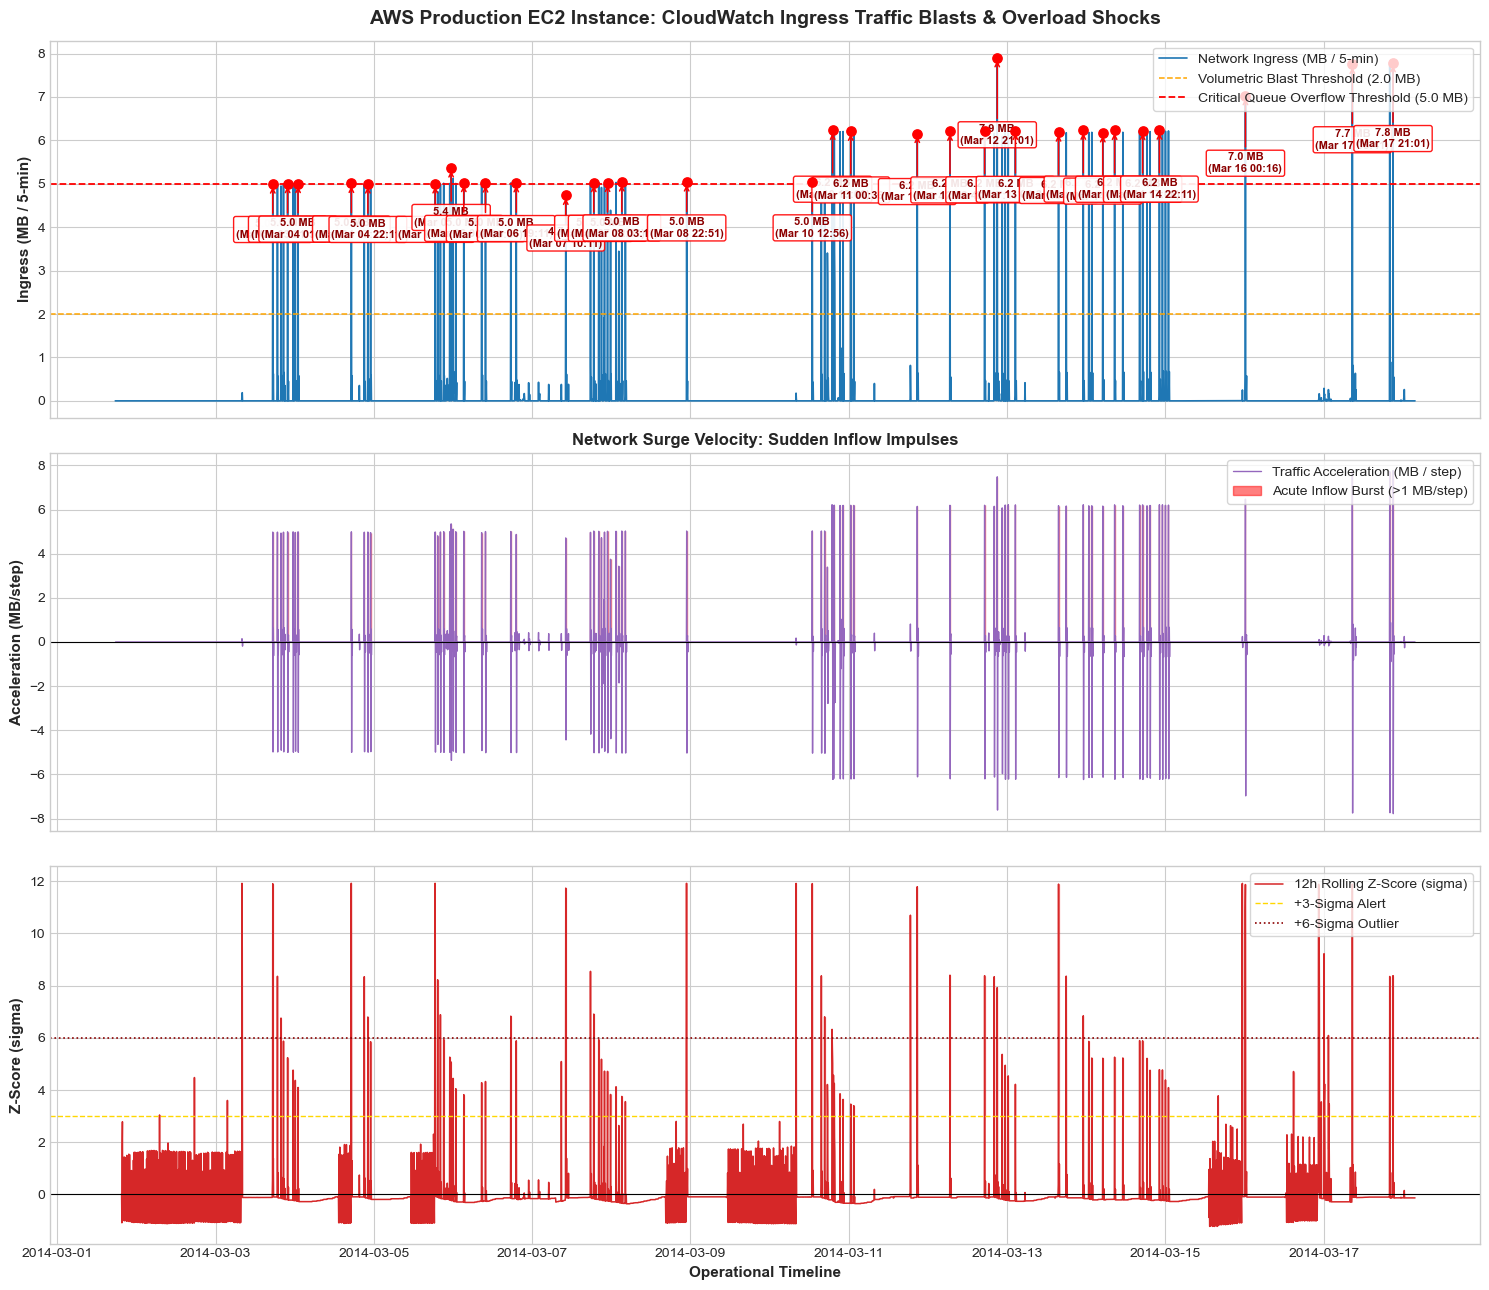

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# 1. Network Ingress Traffic Timeline (MB / 5-min) with Blast Annotations
ax1 = axes[0]
ax1.plot(df_aws_proc['timestamp'], df_aws_proc['network_in_mb'], color='#1f77b4', lw=1.2, label='Network Ingress (MB / 5-min)')
ax1.axhline(2.0, color='orange', ls='--', lw=1.1, label='Volumetric Blast Threshold (2.0 MB)')
ax1.axhline(5.0, color='red', ls='--', lw=1.3, label='Critical Queue Overflow Threshold (5.0 MB)')

for p_idx in peaks:
    ts = df_aws_proc.loc[p_idx, 'timestamp']
    val = df_aws_proc.loc[p_idx, 'network_in_mb']
    ax1.scatter(ts, val, color='red', s=45, zorder=5)
    ax1.annotate(f"{val:.1f} MB\n({ts.strftime('%b %d %H:%M')})", 
                 xy=(ts, val), xytext=(ts, val * 0.75),
                 arrowprops=dict(arrowstyle="->", color='red', lw=1.1),
                 fontsize=8.0, fontweight='bold', color='#8b0000', ha='center',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9, edgecolor='red'))

ax1.set_title("AWS Production EC2 Instance: CloudWatch Ingress Traffic Blasts & Overload Shocks", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Ingress (MB / 5-min)", fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# 2. Traffic Velocity / Rate of Rise (delta KB / 5-min)
ax2 = axes[1]
ax2.plot(df_aws_proc['timestamp'], df_aws_proc['velocity_kb_step'] / 1024.0, color='#9467bd', lw=1.0, label='Traffic Acceleration (MB / step)')
ax2.axhline(0, color='black', lw=0.8)
ax2.fill_between(df_aws_proc['timestamp'], 0, df_aws_proc['velocity_kb_step'] / 1024.0, 
                 where=(df_aws_proc['velocity_kb_step'] > 1024), color='red', alpha=0.5, label='Acute Inflow Burst (>1 MB/step)')
ax2.set_ylabel("Acceleration (MB/step)", fontsize=11, fontweight='bold')
ax2.set_title("Network Surge Velocity: Sudden Inflow Impulses", fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

# 3. Rolling 12-Hour Standardized Z-Score
ax3 = axes[2]
ax3.plot(df_aws_proc['timestamp'], df_aws_proc['traffic_zscore_12h'], color='#d62728', lw=1.1, label='12h Rolling Z-Score (sigma)')
ax3.axhline(0, color='black', lw=0.8)
ax3.axhline(3.0, color='gold', ls='--', lw=1.0, label='+3-Sigma Alert')
ax3.axhline(6.0, color='darkred', ls=':', lw=1.2, label='+6-Sigma Outlier')
ax3.fill_between(df_aws_proc['timestamp'], 3.0, df_aws_proc['traffic_zscore_12h'], 
                 where=(df_aws_proc['traffic_zscore_12h'] >= 3.0), color='red', alpha=0.3)
ax3.set_ylabel("Z-Score (sigma)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Operational Timeline", fontsize=11, fontweight='bold')
ax3.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('data/aws_traffic_spikes_timeline.png', dpi=300)
plt.show()

### 7. Ingress Blast Ranking Table & Processed Export

In [5]:
# Summary table of top traffic blasts
blast_df = df_aws_proc[df_aws_proc['is_traffic_blast'] == 1].sort_values('network_in_mb', ascending=False)
blast_table = blast_df[['timestamp', 'network_in_mb', 'velocity_kb_step', 'surge_ratio', 'traffic_zscore_12h']].copy()
blast_table['timestamp'] = blast_table['timestamp'].dt.strftime('%Y-%m-%d %H:%M')
print("=== Top AWS CloudWatch Volumetric Traffic Blasts ===")
print(blast_table.to_string(index=False))

# Export clean processed dataset
out_path = 'data/aws_traffic_spikes_processed.csv'
df_aws_proc.to_csv(out_path, index=False)
print(f"\nProcessed AWS traffic dataset successfully saved to: {out_path}")

=== Top AWS CloudWatch Volumetric Traffic Blasts ===
       timestamp  network_in_mb  velocity_kb_step   surge_ratio  traffic_zscore_12h
2014-03-12 21:01       7.901592       7660.066406 121131.871345            7.924578
2014-03-17 21:01       7.786121       7949.293750 108857.866667            8.380698
2014-03-17 08:41       7.748661       7914.417188 108334.133333           11.889244
2014-03-16 00:16       7.027740       6627.122070 107735.672515           11.872204
2014-03-14 22:11       6.233940       6366.208008  95566.666667            4.780800
2014-03-13 23:06       6.231852       6364.256055  95534.649123            6.843149
2014-03-10 19:06       6.230030         25.615234  95506.725146            5.015682
2014-03-14 08:36       6.227684       6360.214844  95470.760234            5.259542
2014-03-14 17:06       6.226673       6358.899805  95455.263158            5.884199
2014-03-13 02:31       6.226215       6358.470312  95448.245614            4.218345
2014-03-12 17:11       